# DUNE (Discovery by Unsupervised Niche Enrichment)

DUNE is a computational framework for computing niche enrichment scores and subsequently filtering niches for unsupervised analysis


In [1]:
from requirements import *
import numpy as np
import pandas as pd
import scanpy as sc
import pickle
import anndata as ad
from anndata import AnnData
import warnings
from collections import Counter
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.stats import zscore
from scipy.stats import entropy
import seaborn as sns
from scipy.stats import multinomial

warnings.filterwarnings("ignore")

In [2]:
# Load data
adata_xenv1 = sc.read_h5ad(XEN_V1)

### Functions for computing niche enrichment score and niche entropy 

In [3]:
######### Compute niche enrichment scores #########
def getniches(adata, k):
    """
    Compute niche enrichment score for each niche in each sample
    Inputs  1) adata: anndata object with .obs['sample_name'], .obs['ct'], .obsm['spatial']
            2) k: size of niche
            
    Returns 1) df_niche: Dataframe of cell type composition of individual cell niches. Index is the cell ID of the central cell
            2) enrichment_df: Dataframe of niche enrichment scores (under "ratio" column) for each niche in each sample
    """
    df_niche = None
    niche_ids = dict() # key is niche counts, value is niche ID
    niches = dict() # key is sample, value is list of nichecounts
    likelihoods = dict() # key is sample, value is list of likelihoods
    ct_list = list(adata.obs['ct'].unique()) # list of all cell types
    
    for samp in adata.obs['sample_name'].unique():
        print(samp)
        curr_adata = adata[adata.obs['sample_name'] == samp]
        niches[samp] = [] # list of counters for cell types in each niche
        likelihoods[samp] = [] # list of niche likelihoods

        # Multinomial distribution on cell type frequencies for computing niche likelihoods
        ct_probs = {k: v/curr_adata.shape[0] for k,v in Counter(curr_adata.obs['ct']).items()}
        multinom = multinomial(k, list(ct_probs.values()))

        # k-nearest neighbors
        knn = NearestNeighbors(n_neighbors=k - 1) # add back the cell itself
        knn.fit(curr_adata.obsm['spatial'])
        neighbors = knn.kneighbors(return_distance=False)
    
        map_idxtoct = dict(map(lambda i,j : (i,j) , range(curr_adata.shape[0]), curr_adata.obs['ct']))
        
        for idx in range(neighbors.shape[0]):
            # Get cell types within niche of current cell (idx)
            cts = [map_idxtoct[x] for x in neighbors[idx]]
            cts.append(map_idxtoct[idx])
            ct_counts = Counter(cts)
            niches[samp].append(ct_counts)
    
            # Compute likelihood of current niche neighborhood 
            # (using multinomial distribution on cell type frequencies)
            l = multinom.pmf([ct_counts[ct] if ct in ct_counts else 0 for ct in ct_probs.keys()])
            likelihoods[samp].append(l)
                
        dfcurr = pd.DataFrame(columns=ct_list)
        dfcurr = pd.concat([dfcurr, pd.DataFrame(niches[samp])])
        dfcurr = dfcurr.fillna(0)
    
        # assign an ID for each distinct niche composition
        niche_str = [';'.join(map(str,dfcurr.iloc[i,:])) for i in range(dfcurr.shape[0])]
        for n in niche_str:
            if not n in niche_ids:
                niche_ids[n] = len(niche_ids)
        dfcurr['NicheID'] = [niche_ids[n] for n in niche_str]

        dfcurr['likelihood'] = likelihoods[samp]
        dfcurr['ct'] = list(curr_adata.obs['ct'])
        dfcurr['sample'] = samp
        dfcurr.index = curr_adata.obs.index
        df_niche = pd.concat([df_niche, dfcurr])
    
    # Get niche enrichment scores ("ratio") for each niche by sample
    enrichment_df = None
    for samp in df_niche['sample'].unique():
        sampledf = pd.DataFrame(df_niche[df_niche['sample'] == samp]['NicheID'].value_counts(normalize = True))
        sampledf.columns = ['Niche Proportion']
        sampledf['niche_count'] = df_niche[df_niche['sample'] == samp]['NicheID'].value_counts()
        sampledf['NicheID'] = sampledf.index
        
        di = dict(zip(df_niche[df_niche['sample'] == samp]['NicheID'], df_niche[df_niche['sample'] == samp]['likelihood']))
        sampledf['likelihood'] = [di[x] for x in sampledf.index]
        sampledf['ratio'] = (sampledf['Niche Proportion']/sampledf['likelihood'])
        sampledf['sample'] = samp

        enrichment_df = pd.concat([enrichment_df, sampledf])

    return df_niche,enrichment_df
        

######### Entropy based filtering of niches #########
def gene_entropy(x, n_bins=4, base=2):
    """
    Compute Shannon entropy for a single niche enrichment vector across samples using quantile binning
    x: 1D array of niche enrichment values across samples for one niche
    """
    # quantile-based bin edges
    bins = np.quantile(x, np.linspace(0, 1, n_bins + 1))
    bins = np.unique(bins)  # ensure unique edges

    # if no variability: entropy = 0
    if len(bins) <= 2:
        return 0.0

    # Assign values to bins
    digitized = np.digitize(x, bins[1:-1], right=True)

    # Compute probability of each bin
    probs = np.bincount(digitized, minlength=len(bins)-1).astype(float)
    probs = probs / probs.sum()

    # Remove empty bins
    probs = probs[probs > 0]

    # Return entropy
    return -np.sum(probs * (np.log(probs) / np.log(base))) 


           

In [4]:
adata_xenv1.obs['ct'] = adata_xenv1.obs['ct_general']
df_niche,enrichment_df = getniches(adata_xenv1, 5)

region1_0011549
region1_0011552
region2_0011552
region3_0011552
region1_0027612
region1_0027609
region2_0015400
region1_0015399
region1_0027860
region2_0027861
region1_0043106
region1_0043114
region1_0036509
region1_0036579
region1_0042581
region1_0033583
region2_0033583
region2_0042591
region1_0042592
region1_0064838
region2_0064838
region1_0065604
region4_0065604
region1_0065607
region2_0065607
region1_0069145
region2_0069145
region1_0069146
region2_0069146
region1_0069319
region2_0069319
region1_0069320
region2_0069320
region1_0069330
region1_0069331
region1_0069670
region1_0069737
region2_0069737
region1_0069187
region1_0069478
region2_0069478
region1_0069480
region1_0069594
region2_0069594
region1_0069595
region2_0069595
region1_0069641
region2_0069641
region1_0069808
region2_0015858
region1_0015858
region1_0015829
region2_0015829
region2_0069665
region1_0069665
region3_0078989
region2_0078989
region3_0078981
region1_0078989
region1_0078981
region2_0078981
region1_0079272
region2_

In [5]:
enrichment_df

,Niche Proportion,niche_count,NicheID,likelihood,ratio,sample
11,0.063943,10981,11,1.064056e-02,6.009330,region1_0011549
19,0.056023,9621,19,3.675054e-02,1.524422,region1_0011549
1,0.048523,8333,1,5.077183e-02,0.955713,region1_0011549
0,0.039963,6863,0,3.507130e-02,1.139491,region1_0011549
33,0.030414,5223,33,1.211298e-02,2.510833,region1_0011549
...,...,...,...,...,...,...
944,0.000023,1,944,5.557946e-07,41.078218,region1_0079269
1137,0.000023,1,1137,1.122213e-05,2.034466,region1_0079269
2091,0.000023,1,2091,7.703571e-07,29.636970,region1_0079269
2847,0.000023,1,2847,3.734562e-06,6.113448,region1_0079269


### Niche Enrichment Analysis

<Axes: xlabel='niche_count', ylabel='Density'>

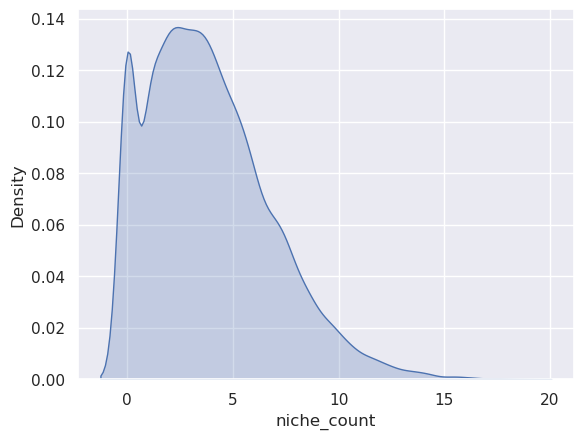

In [6]:
# Density plot of niche counts
sns.kdeplot(np.log2(enrichment_df.groupby('NicheID')['niche_count'].sum()), fill=True)

In [7]:
######## load niche enrichment scores into anndata ########

# remove sparse samples
remove_samples = ['region2_0042591', 'region2_0078981', 'region1_0078989', 'region4_0065604'] # sparse samples, remove
df_niche = df_niche[~(df_niche['sample'].isin(remove_samples))]
enrichment_df = enrichment_df[~(enrichment_df['sample'].isin(remove_samples))]

enrichment_df_new = enrichment_df[enrichment_df['niche_count'] >= 3] # filter out niches that occur < 3 times in a sample
di = dict(zip(adata_xenv1.obs['sample_name'], adata_xenv1.obs['study_id']))
enrichment_df_new['study_id'] = [di[x] for x in enrichment_df_new['sample']]

tmp = enrichment_df_new.loc[:,['NicheID','ratio','sample','study_id']].reset_index()

tmp = pd.DataFrame(tmp.groupby(['NicheID', 'study_id'])['ratio'].mean()) # combines samples of same patient
tmp['ratio'] = np.log2(tmp['ratio']) # log enrichment score
tmp = tmp.unstack()
tmp = tmp.fillna(0)
tmp_raw = tmp.T.droplevel(0)
tmp = tmp.apply(zscore, axis=1) # normalize over samples 
tmp = tmp.T
tmp = tmp.droplevel(0)

ad_niche = AnnData(X=tmp)
ad_niche.layers["raw"] = tmp_raw
type_map = dict(zip(adata_xenv1.obs['study_id'], adata_xenv1.obs['diagnosis']))
ad_niche.obs['diagnosis'] = [type_map[x] for x in ad_niche.obs.index]


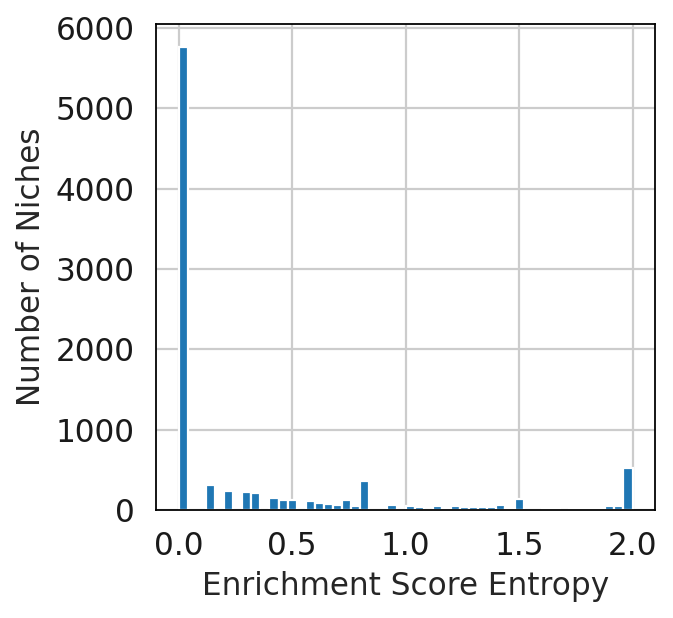

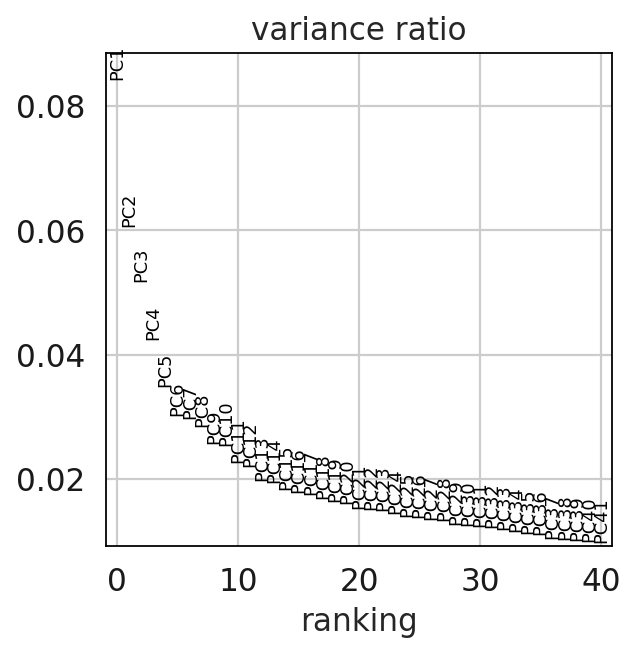

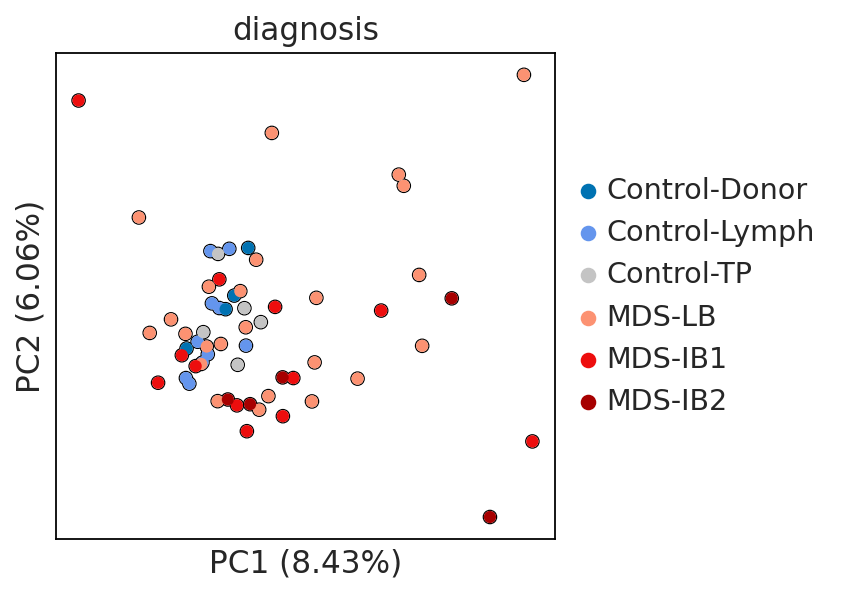

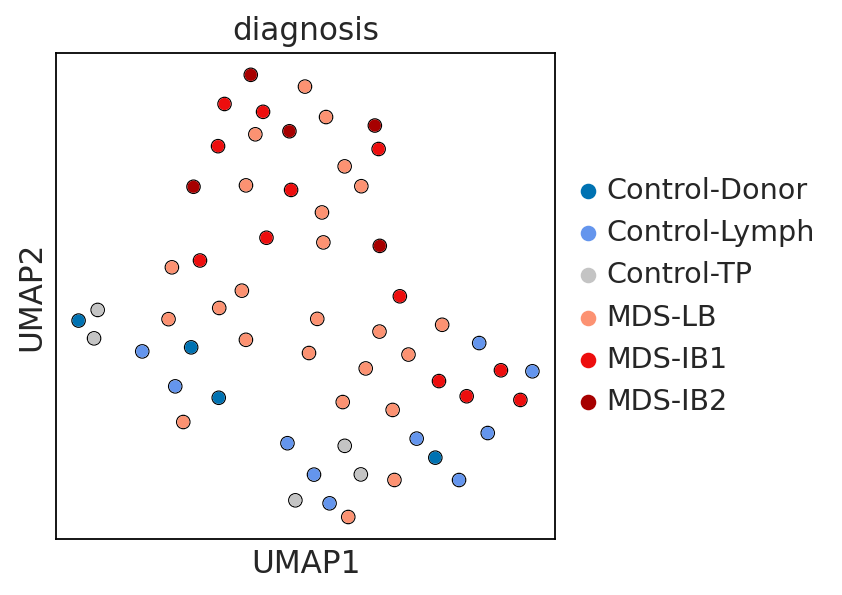

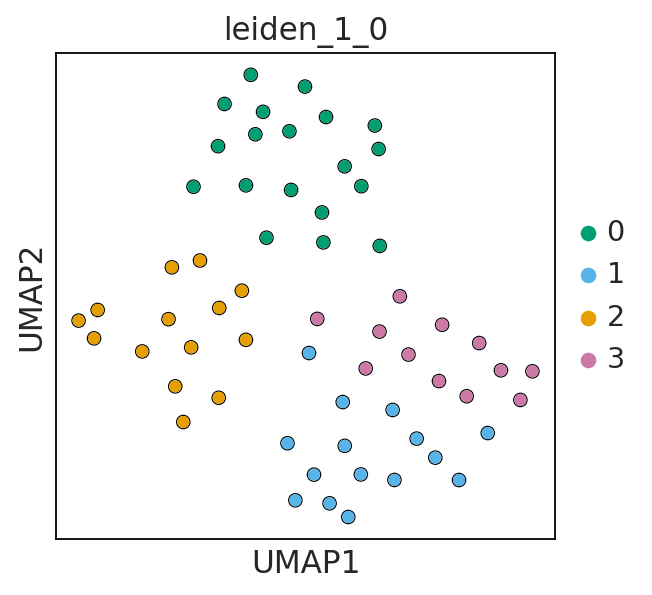

<Figure size 360x320 with 0 Axes>

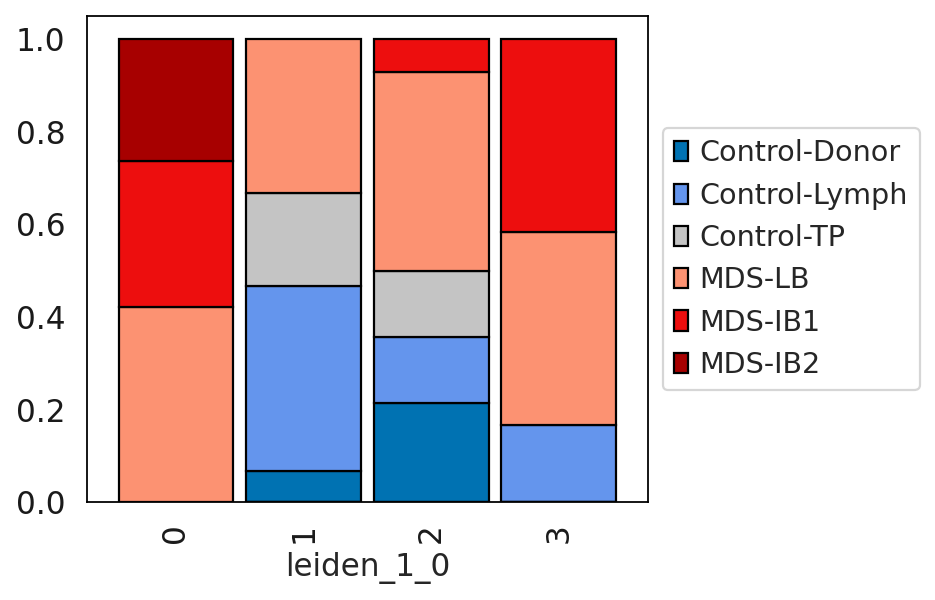

In [9]:
#### Unsupervised analysis of niche enrichment (Main Figure 2B-C and Extended Data Figure 3C) ####

import matplotlib
import matplotlib.pyplot as plt

sc.set_figure_params(figsize=(4, 4))
sc.settings._vector_friendly = True
matplotlib.rcParams['pdf.fonttype'] = 42

show_plot = True
color_dict = {'Control-Donor': "#0072B2", 'Control-Lymph':"#6495ED" , 'Control-TP':"#c4c4c4", 'MDS-LB': "#FC9272", 'MDS-IB1': "#ed0e0e", 'MDS-IB2': "#a70000"}
ad_niche.obs['diagnosis'] = ad_niche.obs['diagnosis'].astype('category').cat.reorder_categories(['Control-Donor','Control-Lymph', 'Control-TP', 'MDS-LB', 'MDS-IB1', 'MDS-IB2'], ordered=True)

######## Filter niches by entropy and variance ########
X = ad_niche.X.toarray() if hasattr(ad_niche.X, "toarray") else ad_niche.X
entropies = np.array([gene_entropy(X[:, j], n_bins=4) for j in range(X.shape[1])])
entropy_series = pd.Series(entropies, index=ad_niche.var_names)
entropy_ranked = entropy_series.sort_values(ascending=False)
entropy_tokeep = entropy_ranked[(entropy_ranked > 0)].index # niche entropy > 0
entropy_tokeep = set([int(x) for x in entropy_tokeep])

plt.hist(entropy_series, bins=50)
plt.xlabel("Enrichment Score Entropy")
plt.ylabel("Number of Niches")
plt.show()

# remove genes with < 1 variance
tokeep = [str(x) for x in (entropy_tokeep - set(np.where(np.array([np.var(ad_niche.layers['raw'][:,i]) for i in range(ad_niche.shape[1])]) < 1)[0]))] 
ad_niche.var["highly_variable"] = ad_niche.var_names.isin(tokeep)

######## PCA ########
sc.tl.pca(ad_niche, svd_solver='arpack')
sc.pl.pca_variance_ratio(ad_niche, log=False, n_pcs = 40)

# plot umap colored by diagnosis
sc.pl.pca(ad_niche, color="diagnosis", size = 120, annotate_var_explained=True, alpha = 1,add_outline= True, outline_width= (0.1, 0),palette= color_dict, components=["1,2"], show=show_plot, sort_order=True)

######## Leiden Clustering and UMAP ########
sc.pp.neighbors(ad_niche, n_neighbors=5, n_pcs=15)
sc.tl.leiden(ad_niche,resolution=1,key_added='leiden_1_0')
sc.tl.paga(ad_niche, groups = 'leiden_1_0')
sc.pl.paga(ad_niche, plot=False)
sc.tl.umap(ad_niche, init_pos='paga', min_dist=0.5)

# plot umap colored by diagnosis
sc.pl.umap(ad_niche, color="diagnosis", size = 120,add_outline= True, alpha = 1,outline_width= (0.1, 0), palette= color_dict, show=show_plot)

# plot umap colored by leiden cluster
sc.pl.umap(ad_niche, color="leiden_1_0", size = 120,add_outline= True, alpha = 1,outline_width= (0.1, 0), show=show_plot, 
           palette = {'0':"#009E73", '1':"#56B4E9", '2':"#E69F00",'3': "#CC79A7",'4':"#F0E442", '5': "#D55E00"})

# bar plot of leiden clusters colored by diagnosis
df_tmp = pd.crosstab(index=ad_niche.obs['leiden_1_0'], columns=ad_niche.obs['diagnosis'])#.apply(lambda x: x/x.sum(), axis=1)
sc.set_figure_params(figsize=(4.5, 4))
f = plt.figure()
df_tmp.apply(lambda x: x/x.sum(), axis=1).plot(kind='bar', stacked=True, width = 0.9, color= color_dict, edgecolor='black')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)



## Cell type composition by leiden cluster

<Figure size 360x320 with 0 Axes>

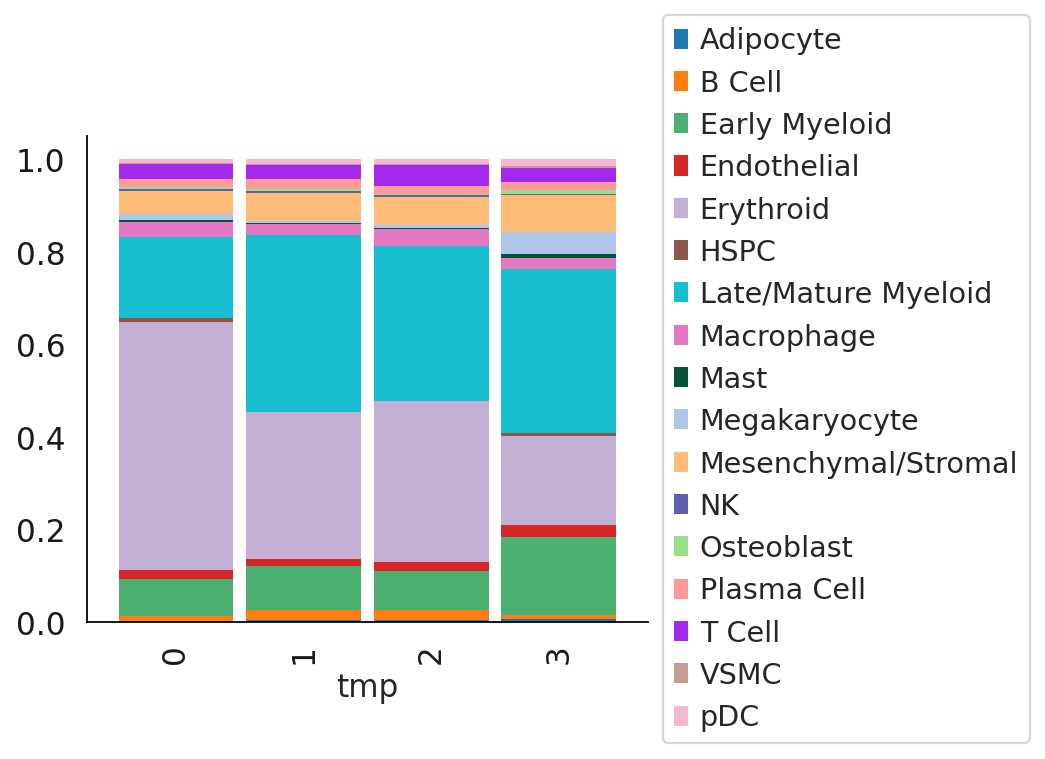

In [14]:
sc.set_figure_params(figsize=(4.5, 4))

f = plt.figure()
di = dict(zip(ad_niche.obs.index, ad_niche.obs['leiden_1_0']))
adata_xenv1.obs['tmp'] = [di[x] if x in di else 'NA' for x in adata_xenv1.obs['study_id']]
tmp = adata_xenv1[adata_xenv1.obs['tmp'] != 'NA']
df = pd.crosstab(index=tmp.obs['tmp'], columns=tmp.obs['ct_general'])

df = df.apply(lambda x: x/x.sum(), axis=1)
cmp = matplotlib.colors.ListedColormap(["#1f77b4", "#ff7f0e", "#4db073","#d62728", "#c5b0d5",'#8c564b', "#17becf", "#e377c2", "#035239", "#aec7e8", "#ffbb78",'#615db0',"#98df8a", "#ff9896","#a42aeb","#c49c94", "#f7b6d2"])

g = df.plot(kind='bar', stacked=True, width = 0.9, colormap= cmp, edgecolor= 'none')
g.spines['top'].set_visible(False)
g.spines['right'].set_visible(False)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()


## Differentially enriched niches

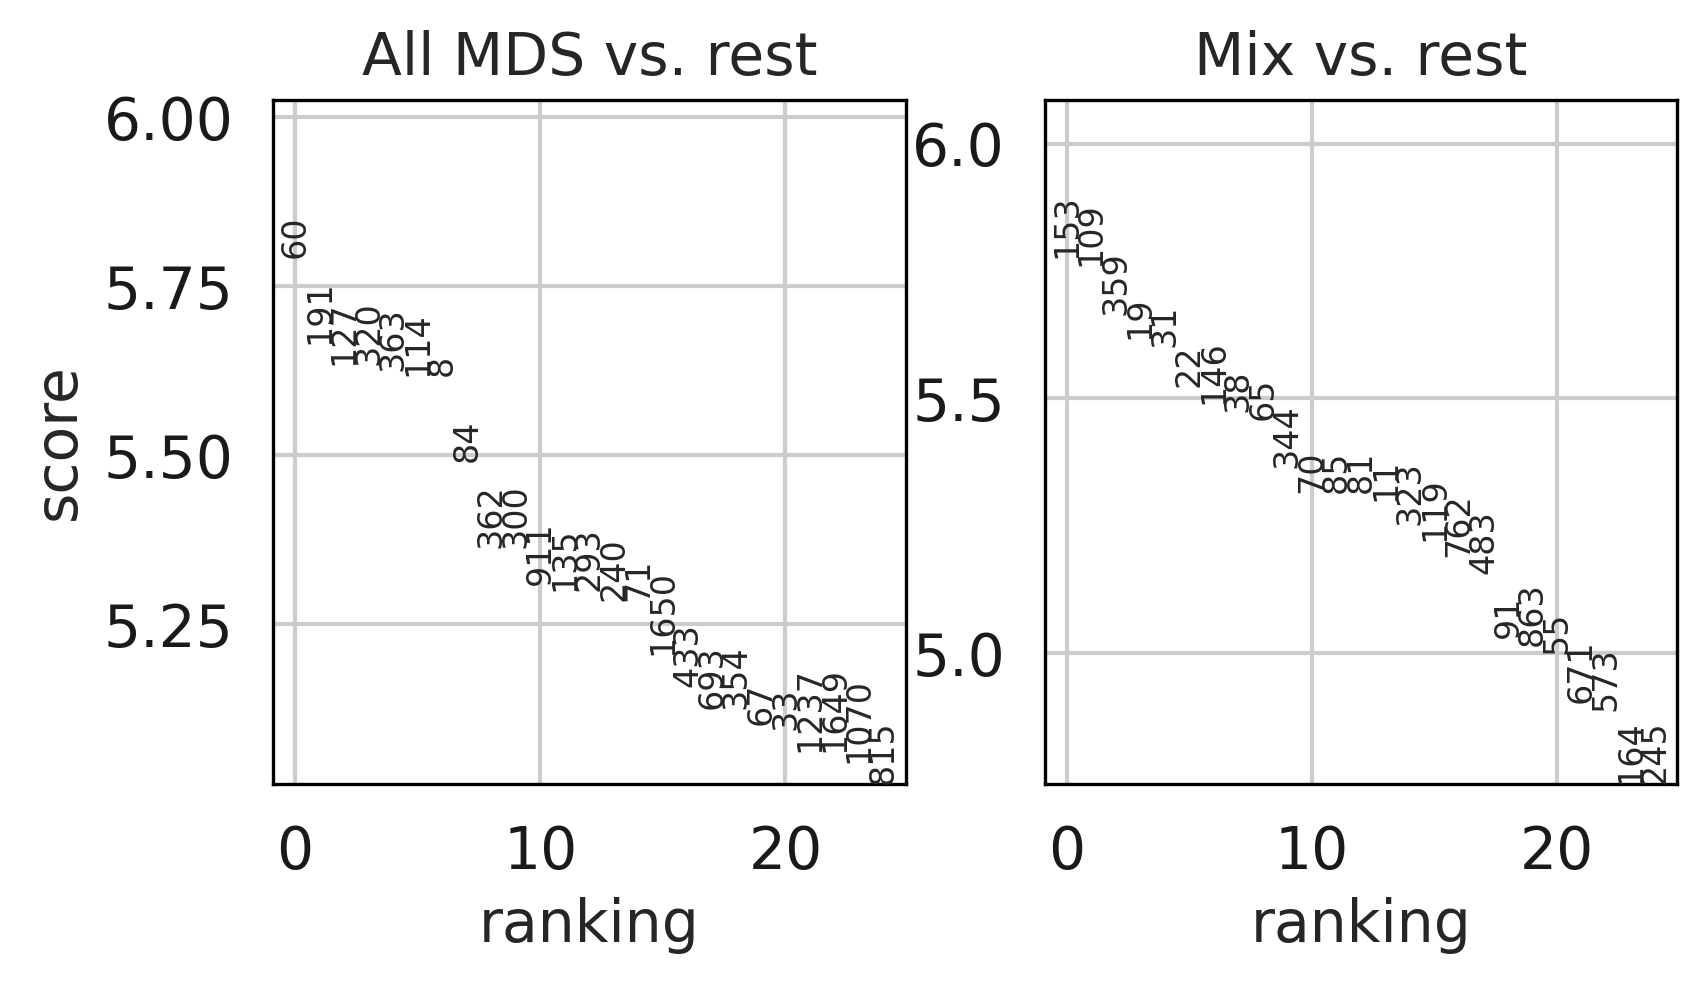

In [17]:
#### Differential niche enrichment: Leiden cluster 0 vs rest ####
ad_niche.obs['cluster'] = 'Mix'
ad_niche.obs['cluster'][ad_niche.obs['leiden_1_0'].isin(['0'])] = 'All MDS'
sc.set_figure_params(scanpy=True, dpi=150,figsize=(3,3))
sc.tl.rank_genes_groups(ad_niche, groupby="cluster", method='wilcoxon',use_raw= False)
sc.pl.rank_genes_groups(ad_niche, n_genes=25, sharey=False)

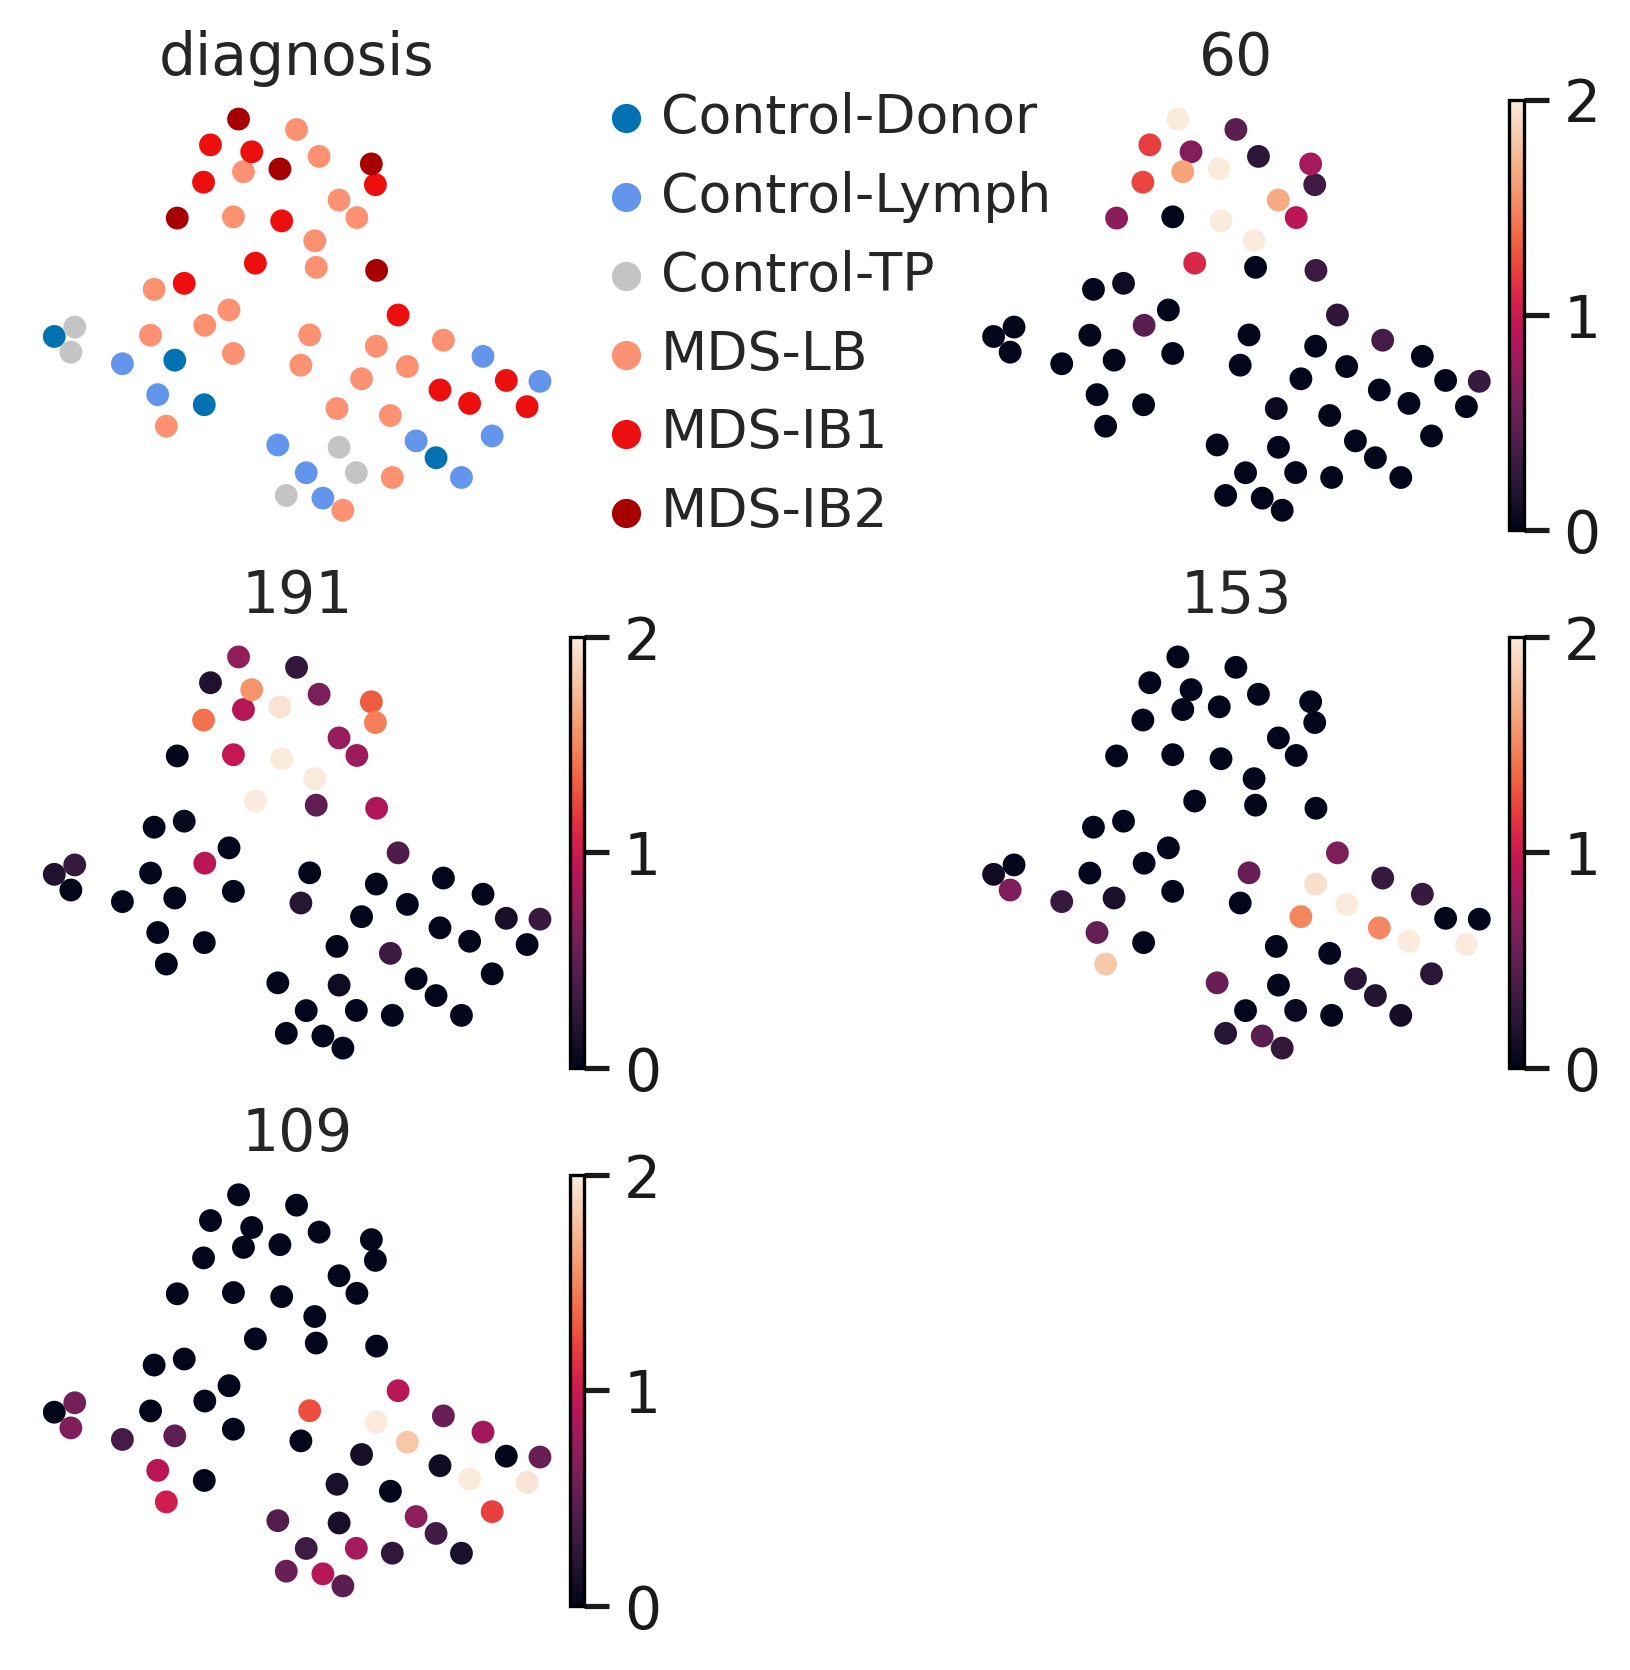

In [18]:
#### Visualize top differentially enriched niches on UMAP ####
sc.set_figure_params(scanpy=True, dpi=150,figsize=(2,2))
sc.pl.umap(
    ad_niche, 
    color=['diagnosis', '60', '191', '153','109'], 
    frameon=False,
    wspace=0.6, ncols=2,vmin = 0, vmax = 2, sort_order = True, size = 120,
    neighbors_key='WNN'
)

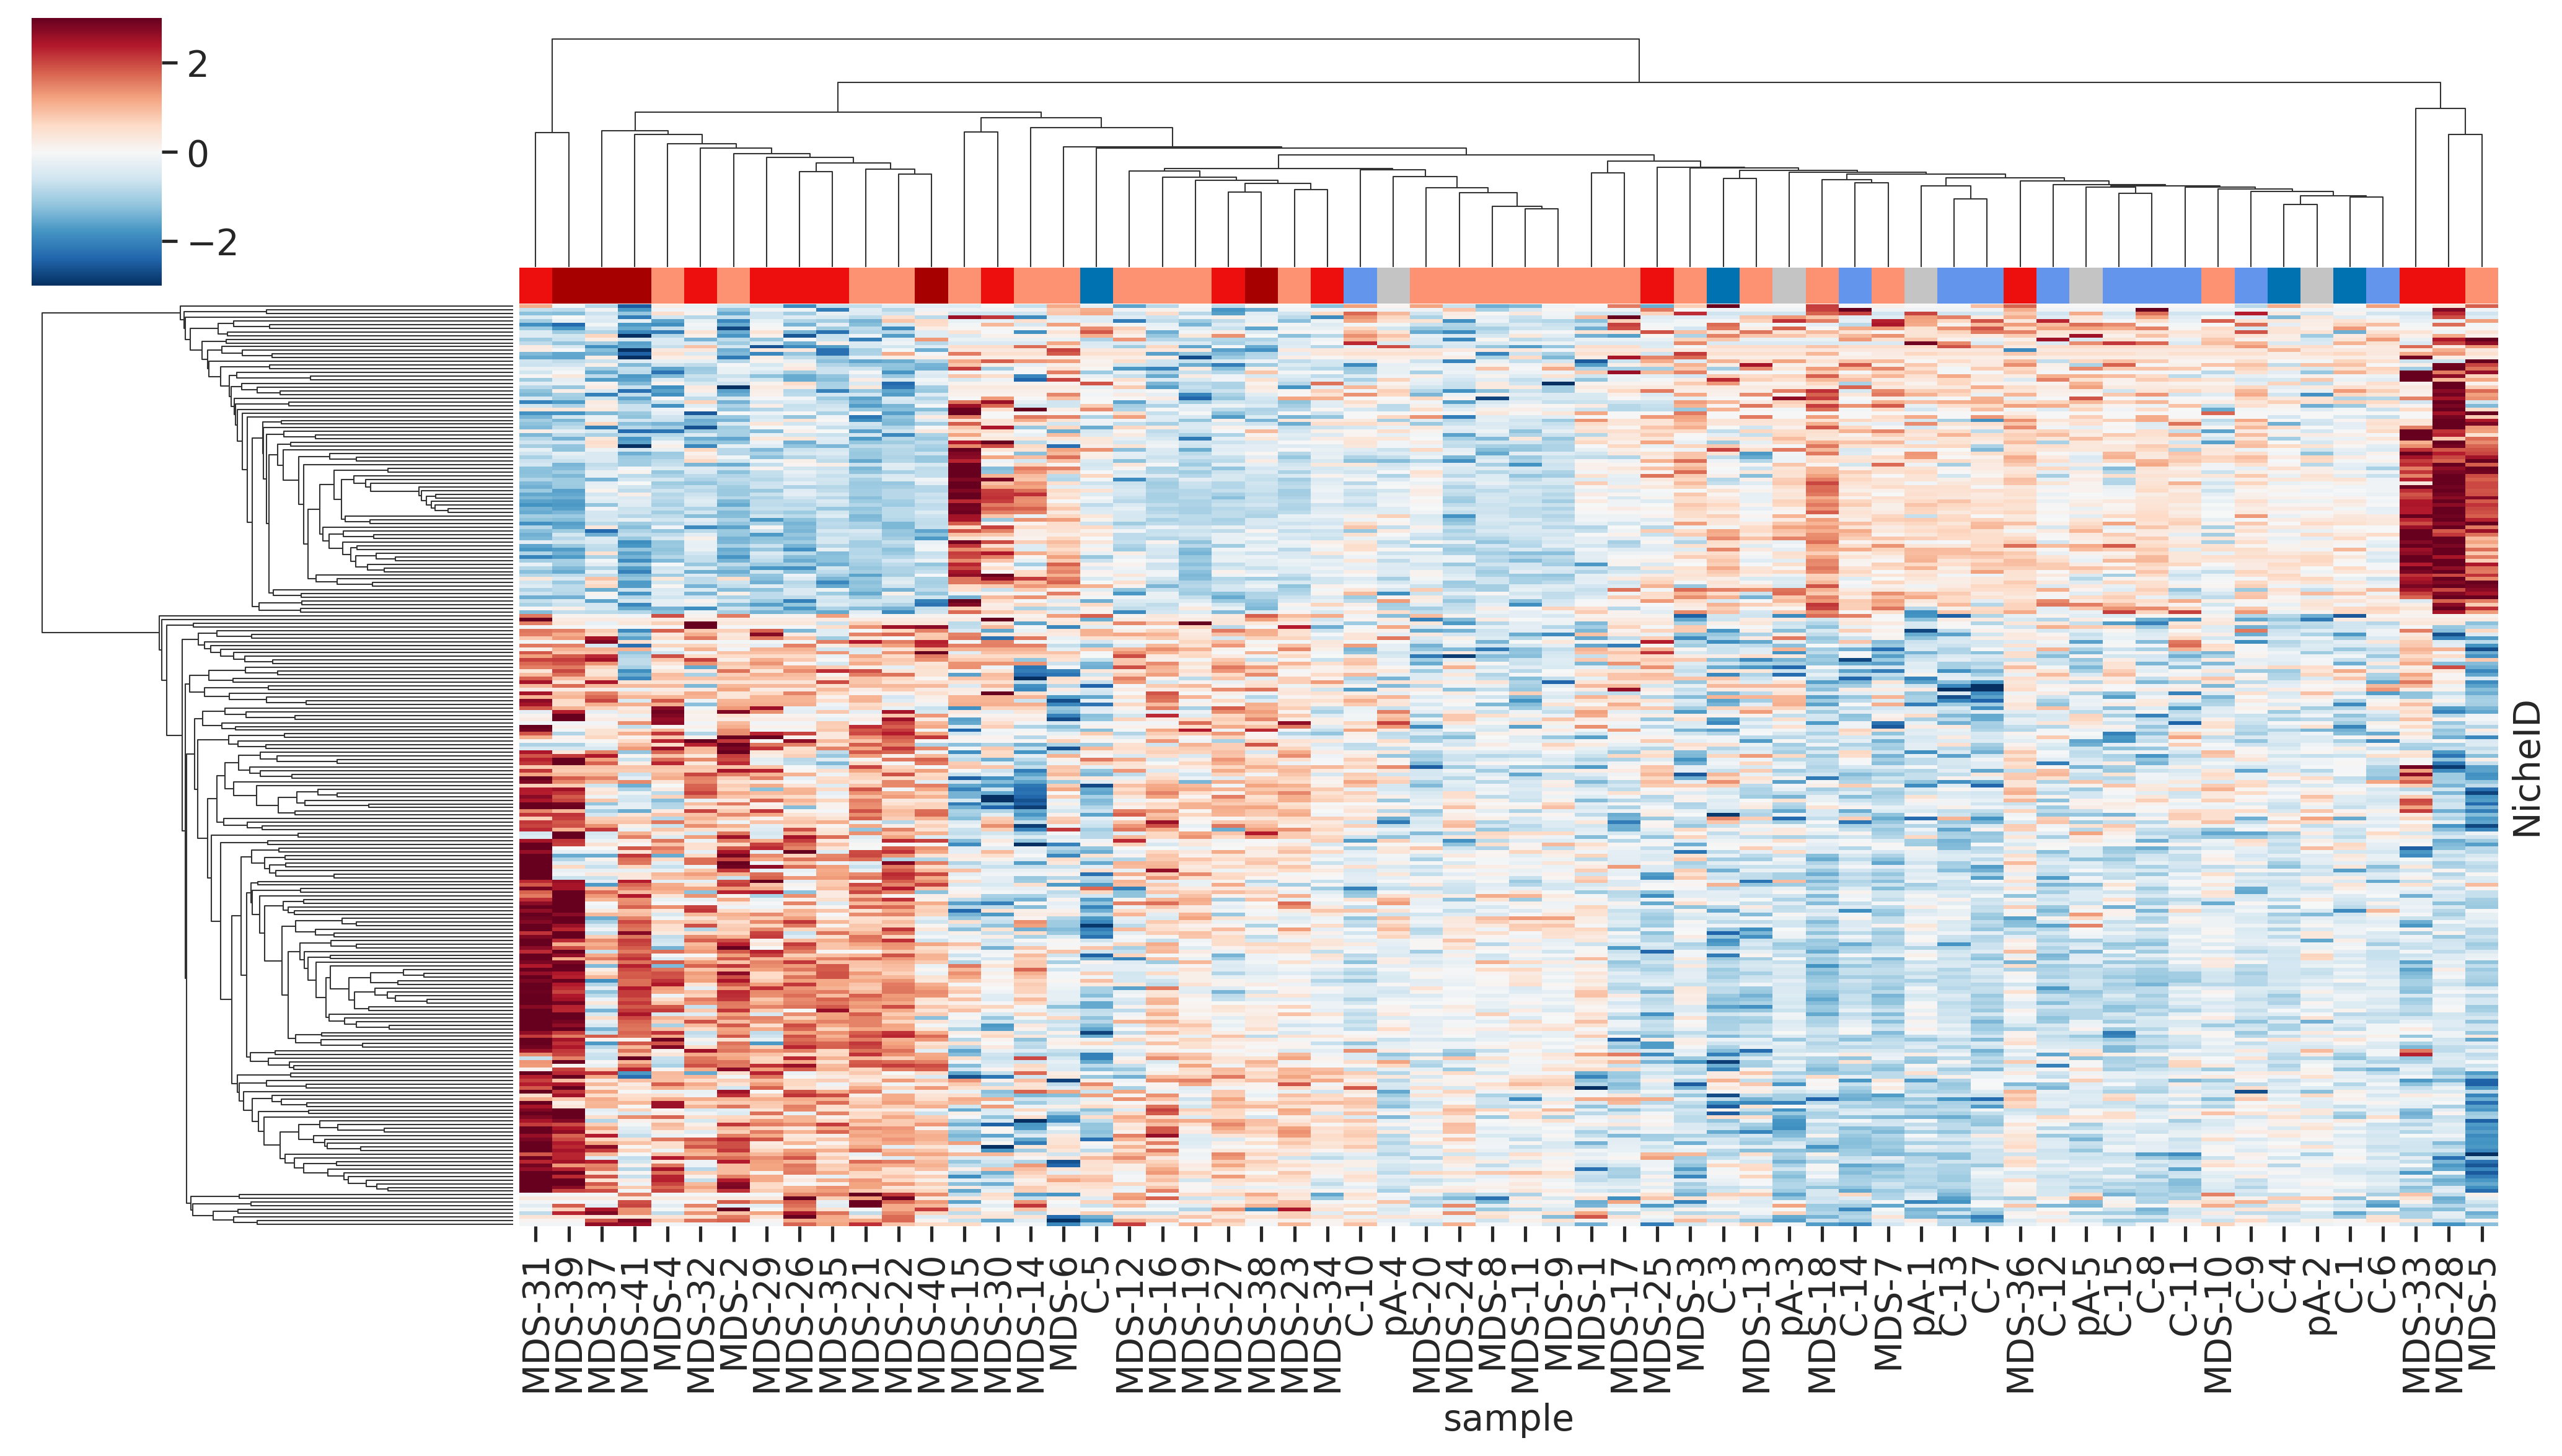

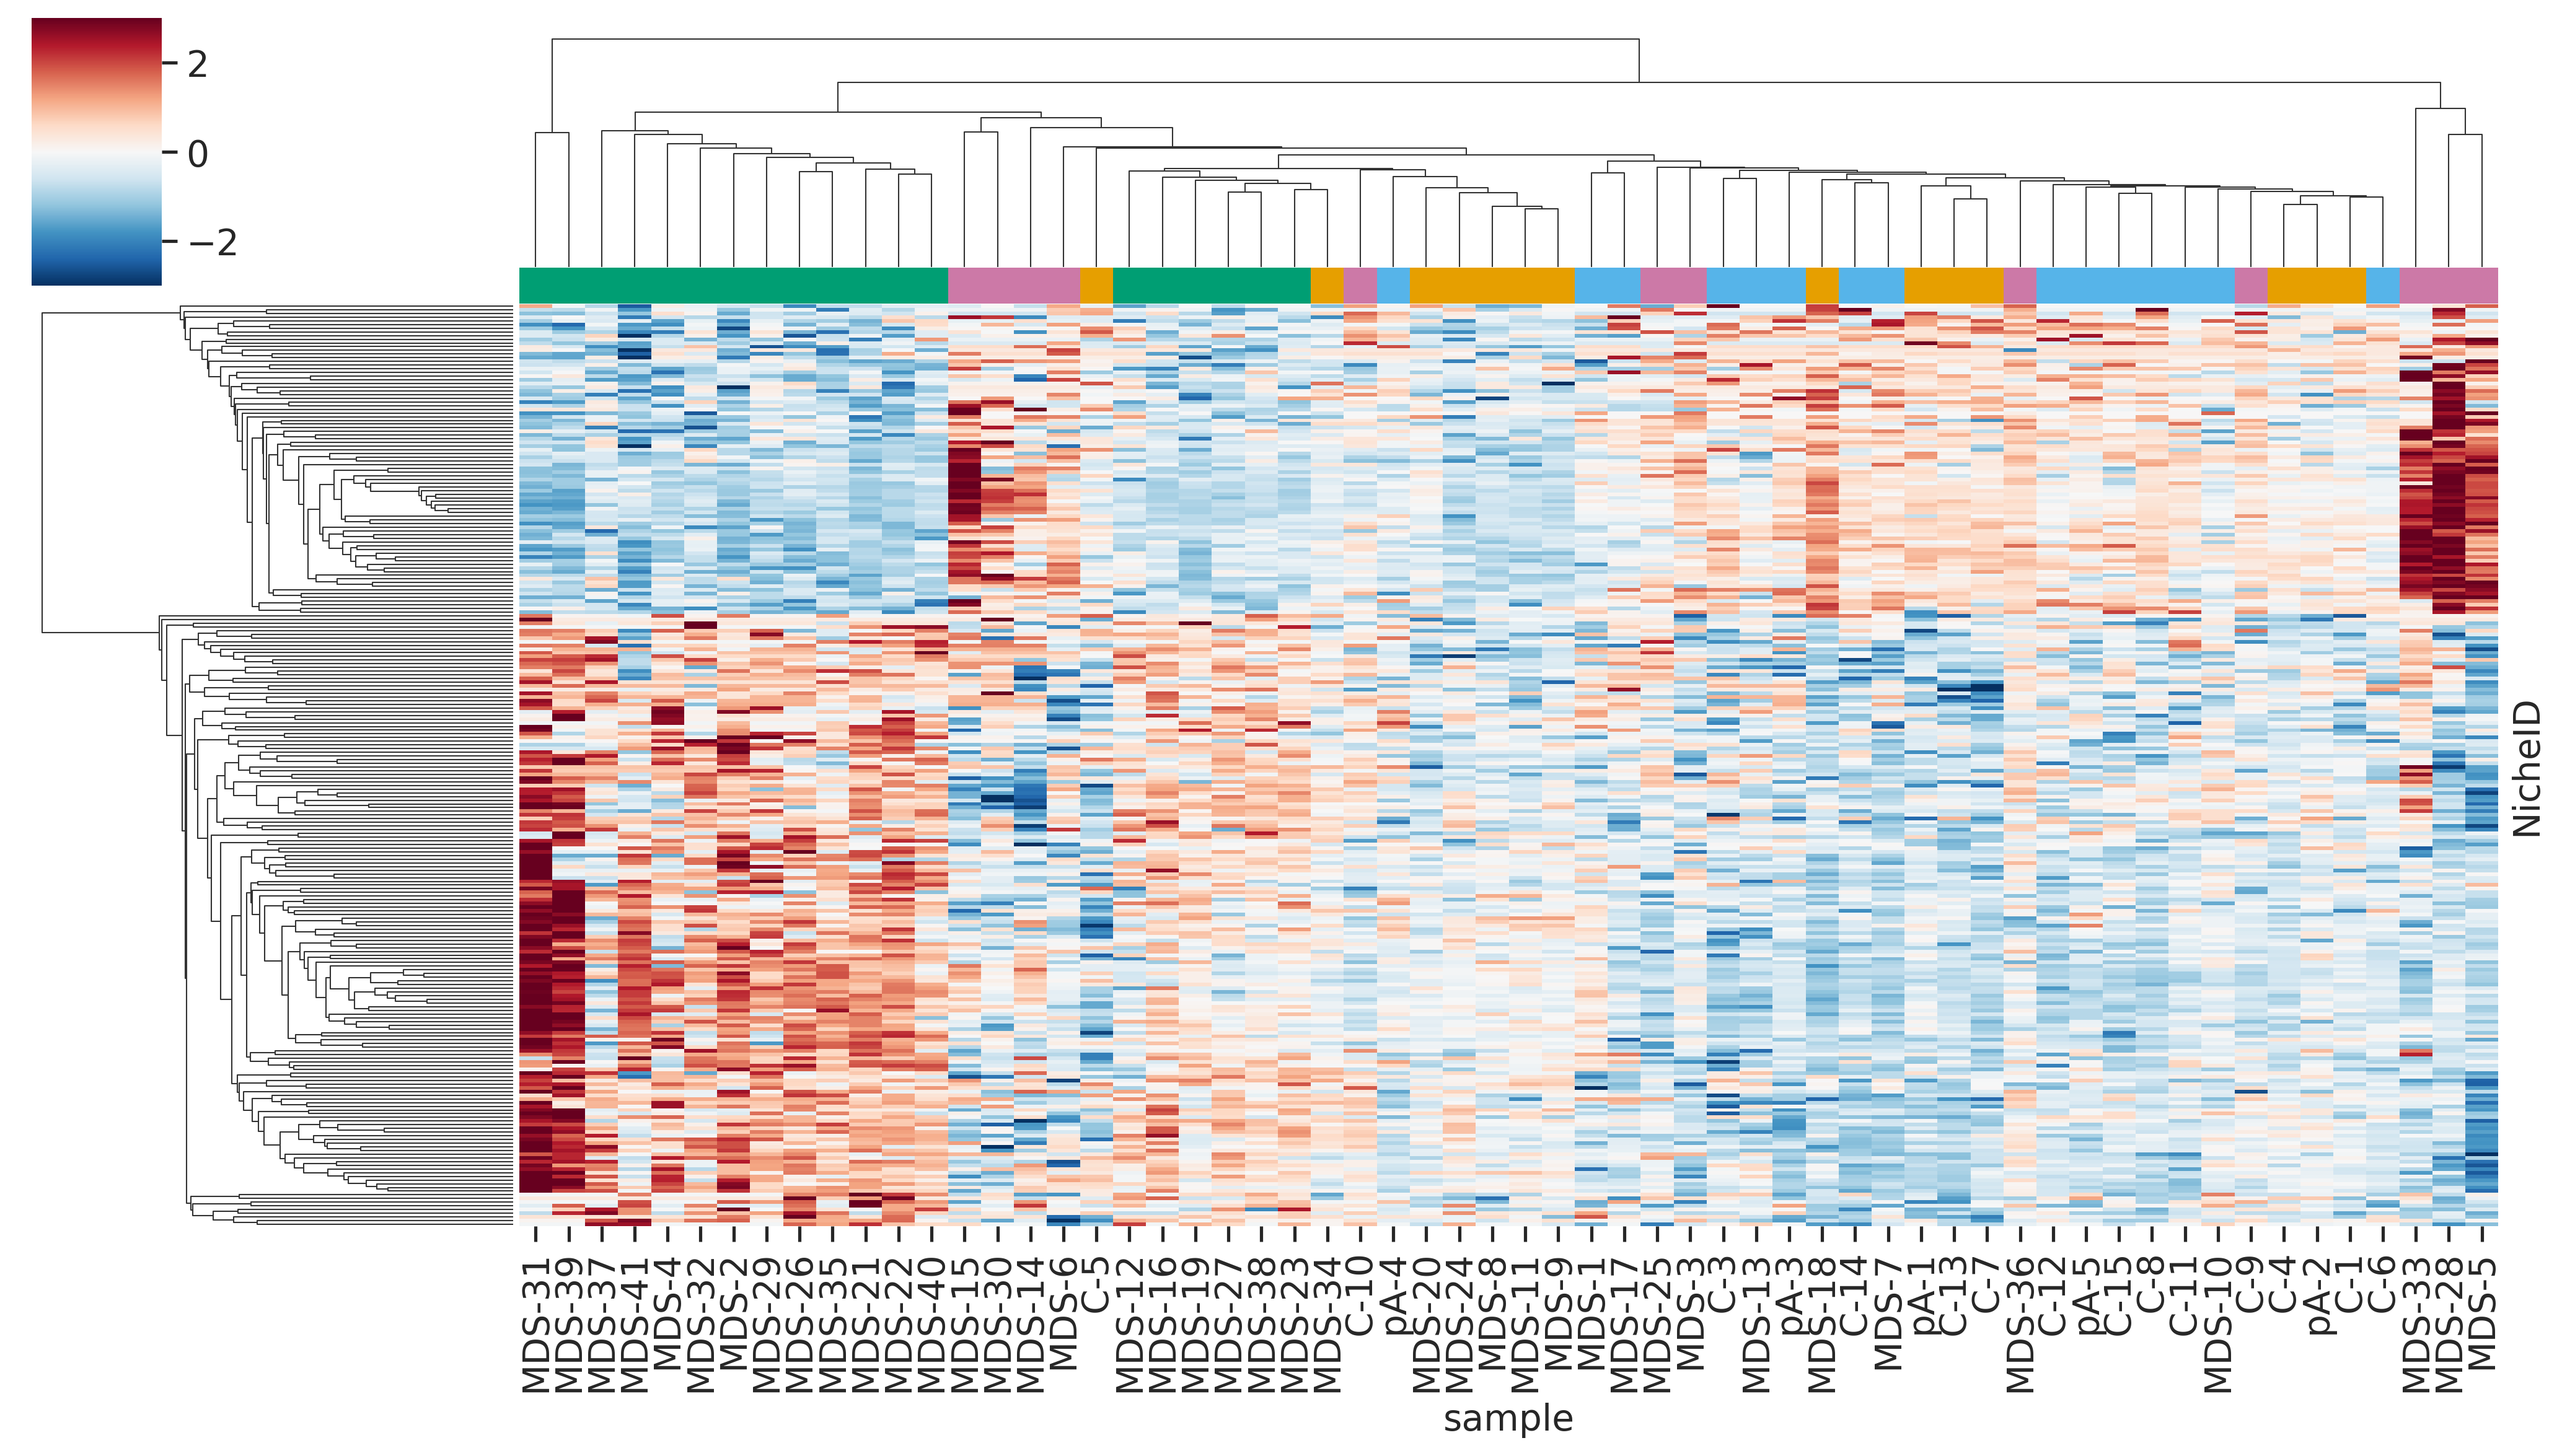

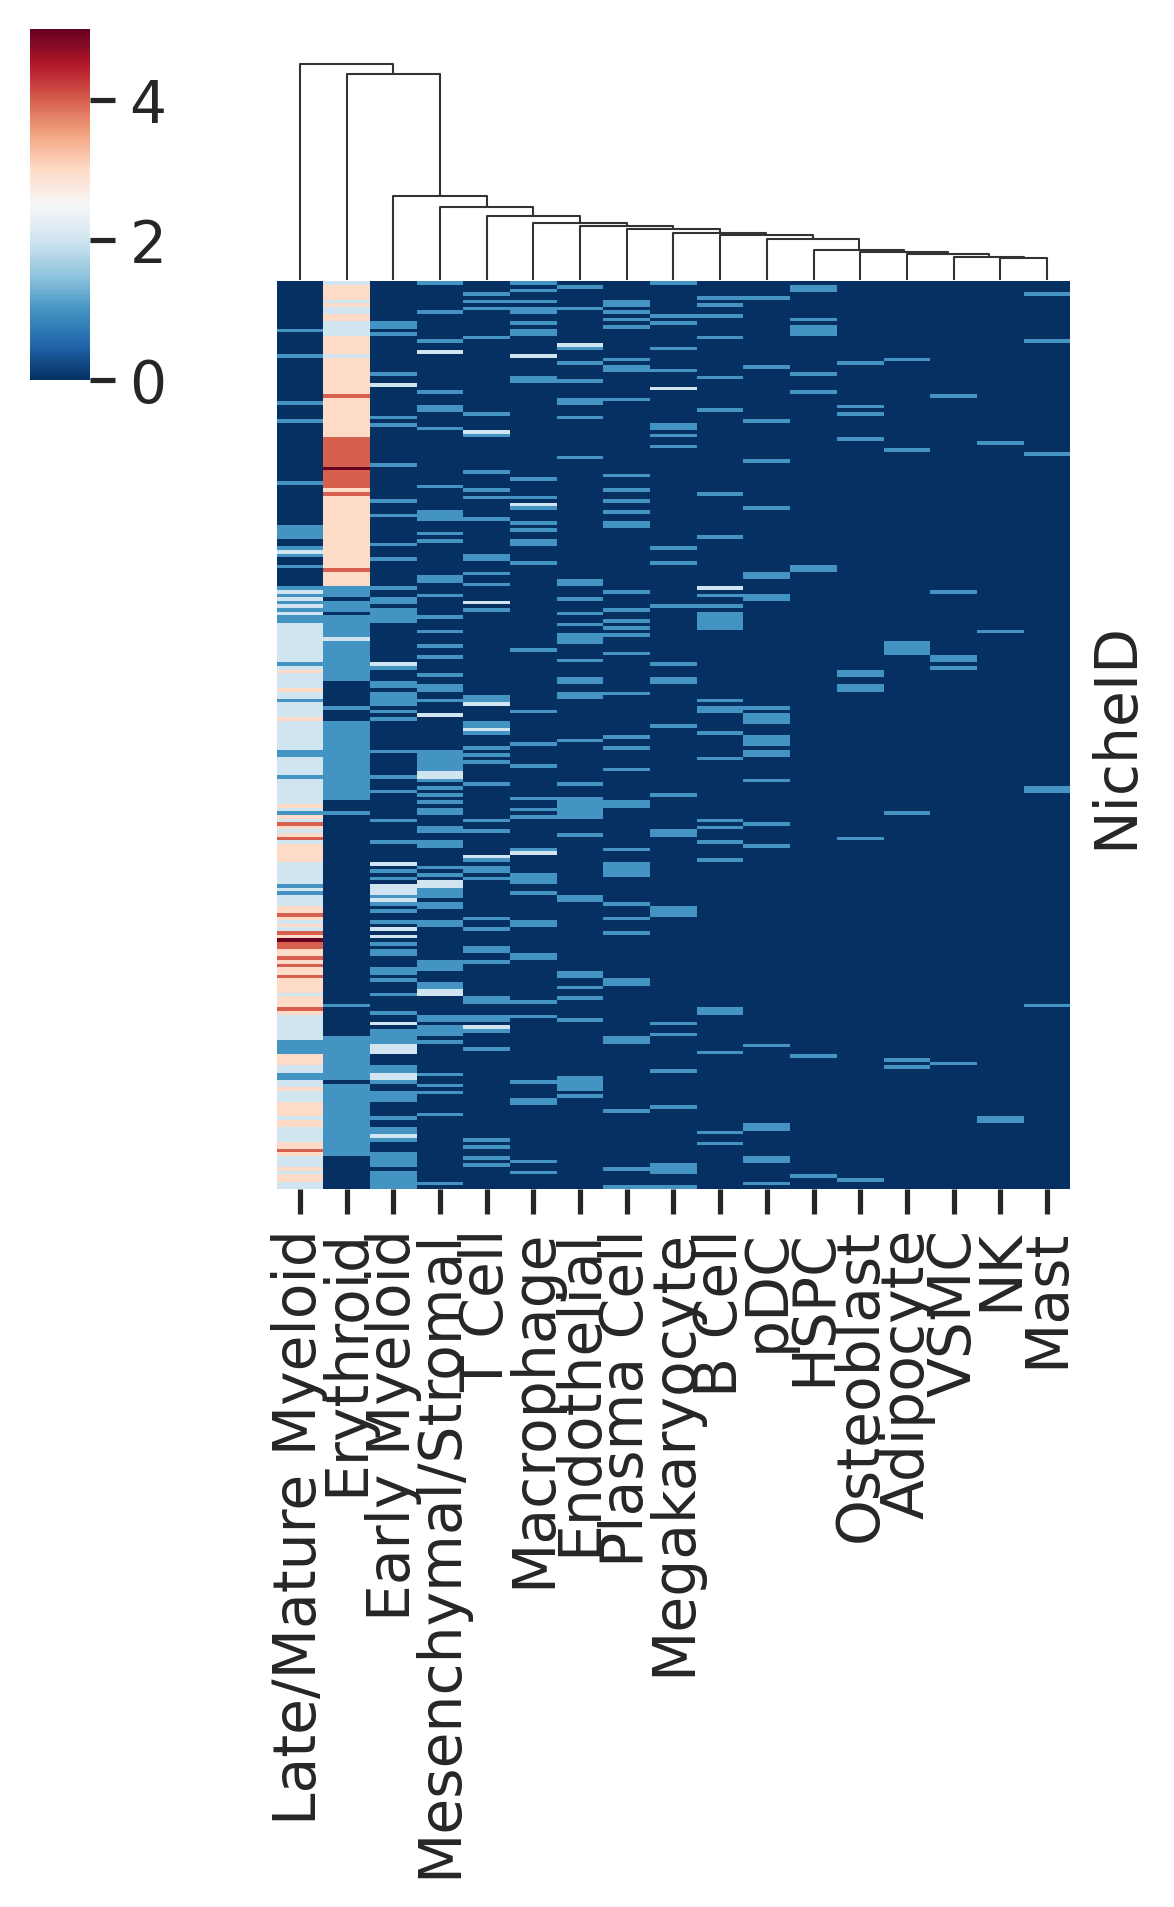

In [21]:
#### Plot heatmap of differentially enriched niches (Extended Data Figure 3D) ####
sns.set_style("whitegrid", {'axes.grid' : False})

# Get differentially enriched niches
sc.tl.rank_genes_groups(ad_niche, groupby="cluster", method="wilcoxon",layer = 'raw')
tmp = sc.get.rank_genes_groups_df(ad_niche, group="All MDS")
clust_niches = tmp[tmp['pvals_adj'] < 0.05]
tokeep = [int(x) for x in clust_niches['names']]

enrichment_df_fil = enrichment_df[enrichment_df['niche_count'] >= 3]
di = dict(zip(adata_xenv1.obs['sample_name'], adata_xenv1.obs['study_id']))
enrichment_df_fil['sample'] = [di[x] for x in enrichment_df_fil['sample']]

tmp = enrichment_df_fil[enrichment_df_fil['NicheID'].isin(tokeep)]
tmp = pd.DataFrame(tmp.groupby(['NicheID', 'sample'])['ratio'].mean()) # combine samples from the same patient
tmp['ratio'] = np.log2(tmp['ratio'])
tmp = tmp.unstack()
tmp = tmp.fillna(0)
tmp = tmp.apply(zscore, axis=1)
tmp.columns = tmp.columns.get_level_values(1)
cmap = 'RdBu_r'

# heatmap of niche enrichment scores with top bar indicating diagnosis (rows are niches, columns are samples)
type_map = dict(zip(adata_xenv1.obs['study_id'], adata_xenv1.obs['diagnosis']))
lut = {'Control-Donor': "#0072B2", 'Control-Lymph':"#6495ED" , 'Control-TP':"#c4c4c4", 'MDS-LB': "#FC9272", 'MDS-IB1': "#ed0e0e", 'MDS-IB2': "#a70000"}
type_order = [type_map[x] for x in tmp.columns]
col_colors = [lut[x] for x in type_order]
g = sns.clustermap(tmp, row_cluster=True, yticklabels=False,  xticklabels=True, cmap = cmap, figsize=(14, 8), col_colors=col_colors, vmin=-3, vmax=3) #row_colors=row_colors,
g.ax_heatmap.tick_params(axis='x', which='both', bottom=True, top=False)

# heatmap of niche enrichment scores with top bar indicating leiden cluster (rows are niches, columns are samples)
type_map = dict(zip(ad_niche.obs.index, ad_niche.obs['leiden_1_0']))
lut = {'0':"#009E73", '1':"#56B4E9", '2':"#E69F00",'3': "#CC79A7",'4':"#F0E442", '5': "#D55E00"} #{'0': "#1f77b4", '1':"#ff7f0e" , '2':"#2ca02c", '3': "#d62728", '4': "#9467bd"}
type_order = [type_map[x] for x in tmp.columns]
col_colors = [lut[x] for x in type_order]
g = sns.clustermap(tmp, row_cluster=True, yticklabels=False,  xticklabels=True, cmap = cmap, figsize=(14, 8), col_colors=col_colors, vmin=-3, vmax=3) #row_colors=row_colors,
g.ax_heatmap.tick_params(axis='x', which='both', bottom=True, top=False)


# heatmap of composition of niches. Row order corresponds to niches in previous heatmaps
nicheorder = [tmp.index[x] for x in g.dendrogram_row.reordered_ind]
niche_content = df_niche.iloc[:,0:18].drop_duplicates()
niche_content.index = niche_content['NicheID']
niche_content = niche_content.iloc[nicheorder, :]
g = sns.clustermap(niche_content.iloc[:,0:17], row_cluster=False, yticklabels=False, cmap = cmap, xticklabels=True, figsize=(4, 6.5)) #row_colors=row_colors,
g.ax_heatmap.tick_params(axis='x', which='both', bottom=True, top=False)


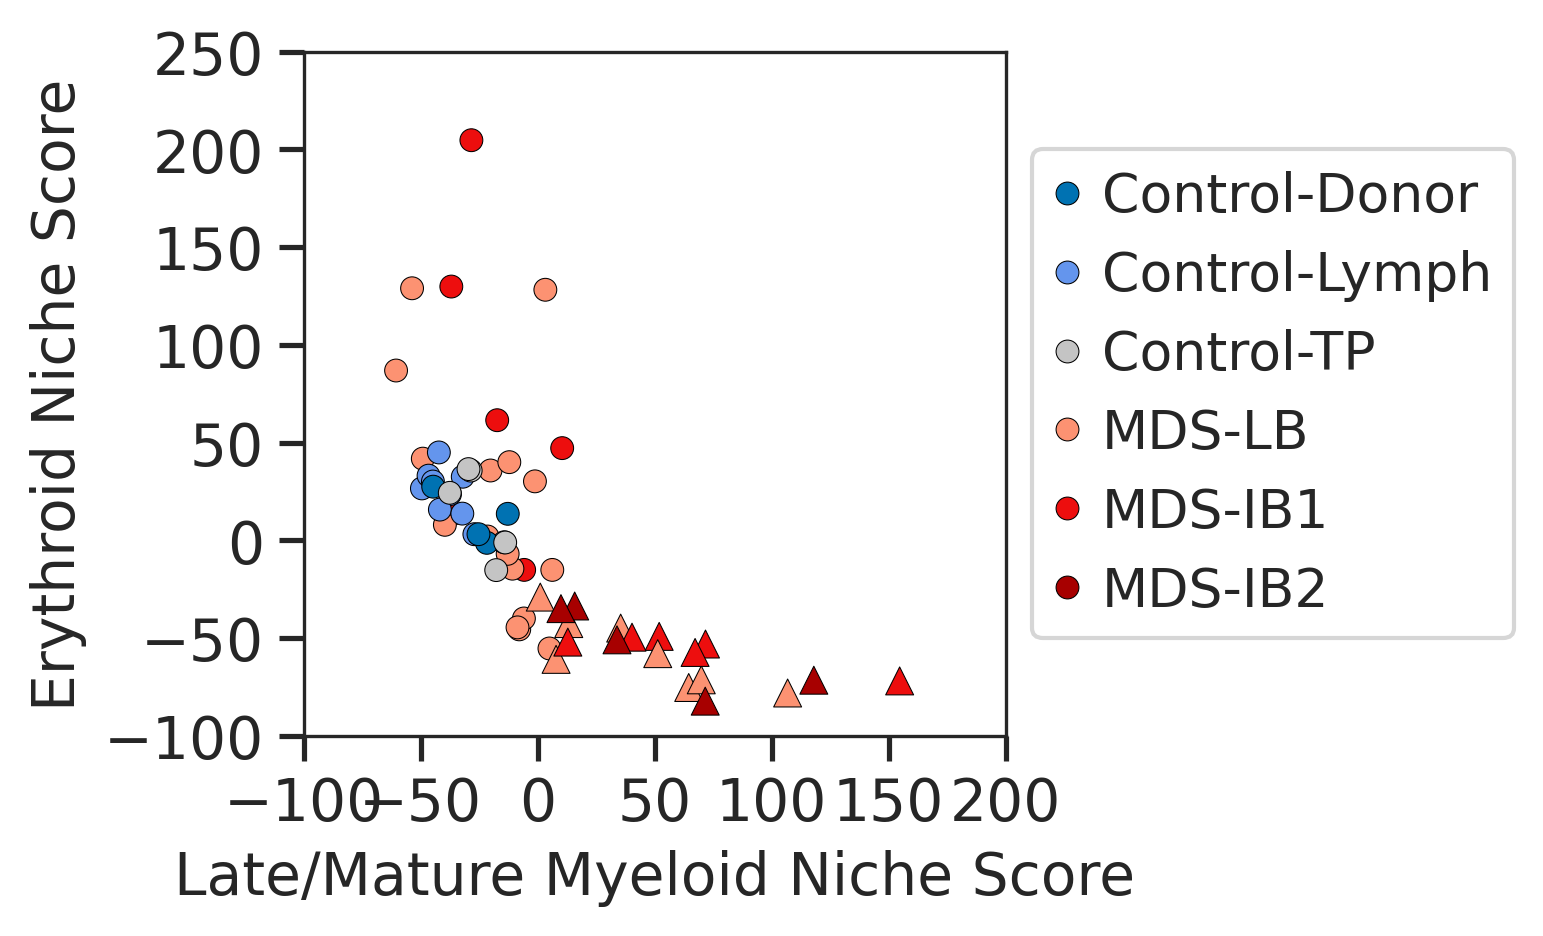

In [33]:
# Scatterplot: Late/Mature Myeloid Niche Score vs Erythroid Niche Score

plt.figure(figsize=(3,3))

sc.tl.rank_genes_groups(ad_niche, groupby="cluster", method="wilcoxon",layer = 'raw')
tmp = sc.get.rank_genes_groups_df(ad_niche, group="All MDS")
clust_niches = tmp[tmp['pvals_adj'] < 0.05]

tokeep = [int(x) for x in clust_niches['names']]

currdf_fil = enrichment_df[enrichment_df['niche_count'] >= 3]
di = dict(zip(adata_xenv1.obs['sample_name'], adata_xenv1.obs['study_id']))
currdf_fil['sample'] = [di[x] for x in currdf_fil['sample']]

tmp = currdf_fil[currdf_fil['NicheID'].isin(tokeep)]
tmp = pd.DataFrame(tmp.groupby(['NicheID', 'sample'])['ratio'].mean()) # combines samples of same patient
tmp['ratio'] = np.log2(tmp['ratio'])
tmp = tmp.unstack()
tmp = tmp.fillna(0)
tmp = tmp.apply(zscore, axis=1)
tmp.columns = tmp.columns.get_level_values(1)

cmap = 'RdBu_r'


#### Sum enrichment scores for erythroid dominant vs myeloid dominant niches
niche_content = df_niche.iloc[:,0:18].drop_duplicates()
niche_content.index = niche_content['NicheID']

k = 5 

s1 = tmp[tmp.index.isin([int(x) for x in niche_content[niche_content['Late/Mature Myeloid'] > int(int(k)/2)].index])].sum()
s2 = tmp[tmp.index.isin([int(x) for x in niche_content[niche_content['Erythroid'] > int(int(k)/2)].index])].sum()
merged_df = pd.concat([s1, s2], axis=1)
merged_df.columns = ['Late/Mature Myeloid', 'Erythroid']

di = dict(zip(adata_xenv1.obs['study_id'], adata_xenv1.obs['diagnosis']))
merged_df['diagnosis'] = [di[x] for x in merged_df.index]

di = dict(zip(ad_niche.obs.index, ad_niche.obs['cluster']))
merged_df['leiden'] = [di[x] for x in merged_df.index]
merged_df['leiden'][merged_df['leiden'] == 'Mix'] = 'Other'
merged_df['leiden'][merged_df['leiden'] == 'All MDS'] = '0'

merged_df['diagnosis'] = merged_df['diagnosis'].astype('category')
merged_df['diagnosis'] = merged_df['diagnosis'].cat.reorder_categories(['Control-Donor','Control-Lymph','Control-TP', 'MDS-LB','MDS-IB1','MDS-IB2'])

merged_df['group'] = merged_df['diagnosis']
merged_df['group'] = merged_df['group'].cat.reorder_categories(['Control-TP','Control-Donor','Control-Lymph', 'MDS-LB','MDS-IB1','MDS-IB2'])

lut = {'Control-Donor': "#0072B2", 'Control-Lymph':"#6495ED" , 'Control-TP':"#c4c4c4", 'MDS-LB': "#FC9272", 'MDS-IB1': "#ed0e0e", 'MDS-IB2': "#a70000"}

sns.set_style("ticks")
ax = sns.scatterplot(
    data=merged_df[merged_df["leiden"] != "0"].sort_values("group", ascending=False), x="Late/Mature Myeloid", y="Erythroid",
    linewidth=0.25, s=30, hue="diagnosis", palette=lut.values(), marker="o", edgecolor="black", legend=True
)

sns.scatterplot(
    data=merged_df[merged_df["leiden"] == "0"], x="Late/Mature Myeloid", y="Erythroid",
    linewidth=0.25, s=45,
    hue="diagnosis", palette=lut.values(), marker="^", legend=False, edgecolor="black", ax=ax
)

from matplotlib.ticker import MultipleLocator
ax.set_xlabel("Late/Mature Myeloid Niche Score")
ax.set_ylabel("Erythroid Niche Score")
ax.set_xlim(-100, 200)
ax.set_ylim(-100, 250)
ax.xaxis.set_major_locator(MultipleLocator(50))
ax.yaxis.set_major_locator(MultipleLocator(50))
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()
